# 01 · Data audit

Phase 2 of `PLAN.md`: look at the runs before building anything on them. This notebook reads
the compact tables from `scripts/audit_extract.py` (run it first, from the repo root):

```bash
python scripts/audit_extract.py          # all pages -> data/audit/*.parquet
```

Sections, and the question each one answers:

1. **Integrity**: are the pages whole, contiguous, and free of repeats?
2. **Coverage**: how far into the export the snapshot reaches, and runs per build.
3. **Filters**: how many runs survive each filter (co-op, modifiers, mods, abandoned) and
   whether the filtered shares drift by build.
4. **Plausibility**: run times, fast wins, odd starts. Looking for cheats and broken records.
5. **Population mix**: character and ascension mix by build, win rates, death floors,
   and the two uploader groups (runs uploaded by the SlayTheStats mod vs. everything else).
6. **Offers**: skip rates, list sizes, upgraded offers. Checks the assumptions the pick-rate
   design leans on.
7. **Power**: offers per changed card before and after its patch, and a first look at pick
   rates around a few changes.

Definitions used throughout: **solo** = one player; **clean** = no modifiers and no mod
markers; **released** = the build is in `reference/builds.csv` (drops pre-early-access
playtest builds, `-rc.N` release candidates and `NON-RELEASE-VERSION`); **dated before
release** = the run's play date is before its build's release date (probably saved across an
update); **Neow start** = the first floor is Neow (a few launch-build runs skip it).
**primary** = solo + clean + released + not dated before release + Neow start. Abandoned runs stay
in pick-rate work and leave win-rate work.

Plots by build: **stable** builds are filled markers joined by a solid line, **beta** builds are
open markers joined by a dashed line. The two branches are different player populations
playing at the same time, so a jump between a stable and a neighbouring beta build is partly
branch, not patch. Tick labels are colored by branch.

The offer tables (`offer_counts`, `list_counts`) carry the `before_release`, `tagged` and
`neow_start` flags
(re-run `scripts/audit_extract.py` if the setup cell says they're missing), so primary offers
follow the same definition as runs. Section 7 checks how concentrated those runs are.

In [50]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Run from notebooks/ or the repo root
ROOT = pathlib.Path.cwd()
if not (ROOT / "reference").exists():
    ROOT = ROOT.parent
AUDIT = ROOT / "data" / "audit"

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "lines.markersize": 4,
})
pd.set_option("display.width", 140, "display.max_columns", 30)

def vkey(b):
    try:
        return tuple(int(x) for x in b.lstrip("v").split("-")[0].split("."))
    except (ValueError, AttributeError):
        return (999,)

def binom_se(k, n):
    p = k / n
    return np.sqrt(p * (1 - p) / n)

builds = pd.read_csv(ROOT / "reference" / "builds.csv", parse_dates=["release_date"])
builds = builds[~builds.build_id.str.endswith("-beta")]         # update-history aliases
BRANCH = dict(zip(builds.build_id, builds.branch.fillna("unknown")))
RELEASE = dict(zip(builds.build_id, builds.release_date))

runs = pd.read_parquet(AUDIT / "runs.parquet")
pages = pd.read_parquet(AUDIT / "pages.parquet")
offers = pd.read_parquet(AUDIT / "offer_counts.parquet")
lists = pd.read_parquet(AUDIT / "list_counts.parquet")

MOD_COLS = [c for c in runs if c.startswith("mod_")]
runs["branch"] = runs.build_id.map(BRANCH).fillna("not in builds.csv")
runs["solo"] = runs.n_players == 1
runs["modded"] = runs[MOD_COLS].any(axis=1)
runs["clean"] = (runs.n_modifiers == 0) & ~runs.modded
runs["abandoned_at_neow"] = runs.was_abandoned & (runs.floors_reached <= 1)
runs["play_date"] = runs.start_time.dt.tz_convert(None).dt.normalize()
runs["released"] = runs.build_id.isin(BRANCH)                    # in builds.csv
runs["before_release"] = runs.play_date < runs.build_id.map(RELEASE)   # False where no date
runs["primary"] = (runs.solo & runs.clean & runs.released & ~runs.before_release
                  & runs.first_floor_neow)

missing = [c for c in ("before_release", "tagged", "neow_start")
           if c not in offers or c not in lists]
if missing:
    raise ValueError(f"offer tables lack {missing}: re-run scripts/audit_extract.py")

# Offer tables: released builds only
n0 = offers.n.sum()
offers = offers[offers.build_id.isin(BRANCH)]
lists = lists[lists.build_id.isin(BRANCH)]
print(f"offers on non-release builds dropped: {n0 - offers.n.sum():,}")

BUILD_ORDER = sorted(runs.build_id[runs.released].unique(), key=vkey)
NONRELEASE = sorted(set(runs.build_id) - set(BUILD_ORDER), key=vkey)
BRANCH_COLOR = {"stable": "#2a6fdb", "beta": "#e8702a", "unknown": "#8a8a8a",
                "not in builds.csv": "#c9c9c9"}
STYLE = {"stable": dict(ls="-", mfc=None), "beta": dict(ls="--", mfc="white")}
# v0.98.0 (branch unknown, launch build) is drawn with the stable series.
PLOT_BRANCH = {b: ("beta" if BRANCH.get(b) == "beta" else "stable") for b in BUILD_ORDER}


def build_axis(ax):
    """Build ids on the x axis, in version order, tick labels colored by branch."""
    ax.set_xticks(range(len(BUILD_ORDER)), BUILD_ORDER, rotation=60, ha="right")
    for t in ax.get_xticklabels():
        t.set_color(BRANCH_COLOR.get(BRANCH.get(t.get_text(), "unknown"), "#555"))
    ax.set_xlim(-0.6, len(BUILD_ORDER) - 0.4)


def branch_errorbar(ax, df, color, label, min_n=0, scale=1.0, err=True, **kw):
    """Plot df.k / df.n (df indexed by build_id) at BUILD_ORDER positions: stable points
    joined solid with filled markers, beta points joined dashed with open markers. Points
    with n < min_n are left out. Only the first series drawn gets the legend label."""
    df = df.reindex(BUILD_ORDER)
    df = df[df.n >= max(min_n, 1)]
    first = True
    for br in ("stable", "beta"):
        s = df[[PLOT_BRANCH[b] == br for b in df.index]]
        if s.empty:
            continue
        x = [BUILD_ORDER.index(b) for b in s.index]
        y = s.k / s.n * scale
        mfc = STYLE[br]["mfc"] or color
        ax.errorbar(x, y, yerr=binom_se(s.k, s.n) * scale if err else None, color=color,
                    ls=STYLE[br]["ls"], marker="o", mfc=mfc, mec=color, capsize=0,
                    label=label if first else "_nolegend_", **kw)
        first = False


CHARS = ["IRONCLAD", "SILENT", "DEFECT", "REGENT", "NECROBINDER"]
CHAR_COLOR = dict(zip(CHARS, ["#c0392b", "#27ae60", "#2a6fdb", "#e8a02a", "#8e44ad"]))

print(f"{len(runs):,} records, {runs.run_key.nunique():,} distinct runs (seed, start_time), "
      f"{len(pages)} pages, {offers.n.sum():,} card offers on released builds")
print("non-release builds (left out of every plot by build):",
      runs[~runs.released].groupby("build_id").size().reindex(NONRELEASE).to_dict())

offers on non-release builds dropped: 19,245
947,885 records, 727,714 distinct runs (seed, start_time), 949 pages, 86,129,749 card offers on released builds
non-release builds (left out of every plot by build): {'v0.84.0': 2, 'v0.85.1': 1, 'v0.93.2': 1, 'v0.94.1': 1, 'v0.95.3': 3, 'v0.96.0': 3, 'v0.96.1': 4, 'v0.97.0': 10, 'v0.106.0-rc.5': 1, 'v0.107.0-rc.1': 5, 'v0.107.0-rc.2': 4, 'v0.107.1-rc.2': 1, 'v0.109.0-rc.1': 2, 'NON-RELEASE-VERSION': 286}


## 1. Integrity

Every page should hold 1,000 records apart from the occasional short page. Things to look
for: gaps in the page numbers; unreadable lines or truncated files (`bad_lines` ≠ 0);
records repeated across pages (`repeats_dropped`). Repeats would come from the two download
processes that ran at the same time, or from the server. The extractor keeps the first copy.

page range 0 - 948 | 0 missing pages []
bad lines / truncated pages: 0
records repeated across pages (dropped): 0
records per page: {'min': 466.0, '50%': 1000.0, 'max': 1000.0}
duplicate run_hash after extraction: 0 (should be 0)


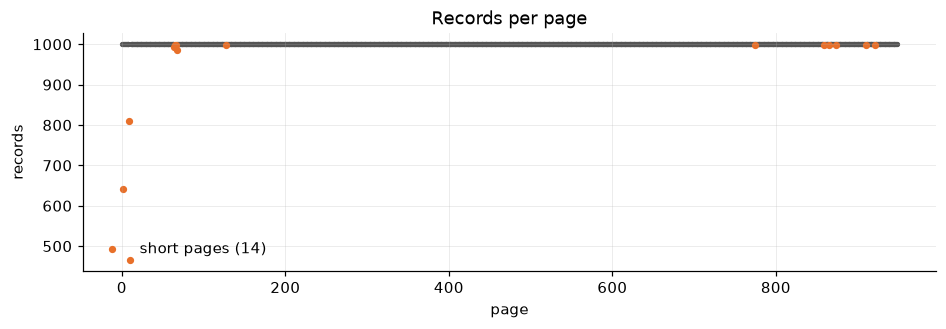

In [51]:
idx = pages.page.to_numpy()
missing = sorted(set(range(idx.min(), idx.max() + 1)) - set(idx))
print("page range", idx.min(), "-", idx.max(), "|", len(missing), "missing pages",
      (missing[:10] + ["..."]) if len(missing) > 10 else missing)
print("bad lines / truncated pages:", int((pages.bad_lines != 0).sum()))
print("records repeated across pages (dropped):", int(pages.repeats_dropped.sum()))
print("records per page:", pages.records.describe()[["min", "50%", "max"]].to_dict())
print("duplicate run_hash after extraction:", int(runs.run_hash.duplicated().sum()), "(should be 0)")

short = pages[pages.records < 1000]
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.scatter(pages.page, pages.records, s=6, color="#555")
ax.scatter(short.page, short.records, s=14, color="#e8702a", label=f"short pages ({len(short)})")
ax.set(xlabel="page", ylabel="records", title="Records per page")
ax.legend(loc="lower left", frameon=False)
plt.show()

## 2. Coverage

The export is ordered by **submission** time, but runs carry only their **play** time
(`start_time`). The plot below shows the spread of play dates in each page. The median
line tells you how far the snapshot has reached. The lower band shows how much old
history gets uploaded late (backfill). If backfill is heavy, a partial snapshot
under-counts recent builds more than old ones.

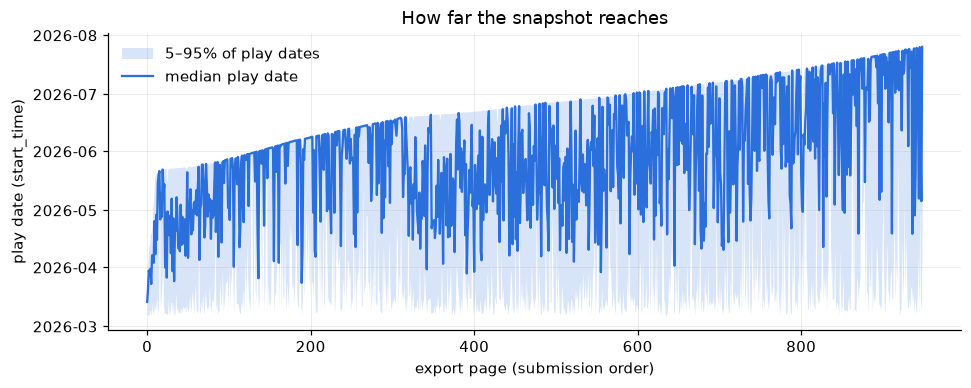

newest play date in snapshot: 2026-07-26 00:59:35+00:00


In [52]:
q = runs.groupby("source_page").start_time.quantile([0.05, 0.5, 0.95]).unstack()
q = q.apply(lambda s: s.dt.tz_convert(None))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.fill_between(q.index, q[0.05], q[0.95], color="#2a6fdb", alpha=0.18, lw=0,
                label="5–95% of play dates")
ax.plot(q.index, q[0.5], color="#2a6fdb", label="median play date")
ax.set(xlabel="export page (submission order)", ylabel="play date (start_time)",
       title="How far the snapshot reaches")
ax.legend(frameon=False, loc="upper left")
plt.show()
print("newest play date in snapshot:", runs.start_time.max())

### How heavy is the backfill?

The export has no submission time, but pages are in submission order, so the newest play
dates on a page approximate when that page was submitted. Upload lag per run = the page's
99th-percentile play date (robust to a few bad clocks) minus the run's own play date.
Caveat: runs played close to where the snapshot ends have had less time to be backfilled,
so lags near the end of the snapshot are cut short.

upload lag (days), primary runs:
0.25      0.1
0.50     18.1
0.75     66.0
0.90     96.4
0.99    125.3
uploaded more than  7 days after being played: 56.8%
uploaded more than 30 days after being played: 43.7%
uploaded more than 90 days after being played: 12.8%
median lag by uploader group (days): {'untagged': 7.1, 'tagged': 59.7}


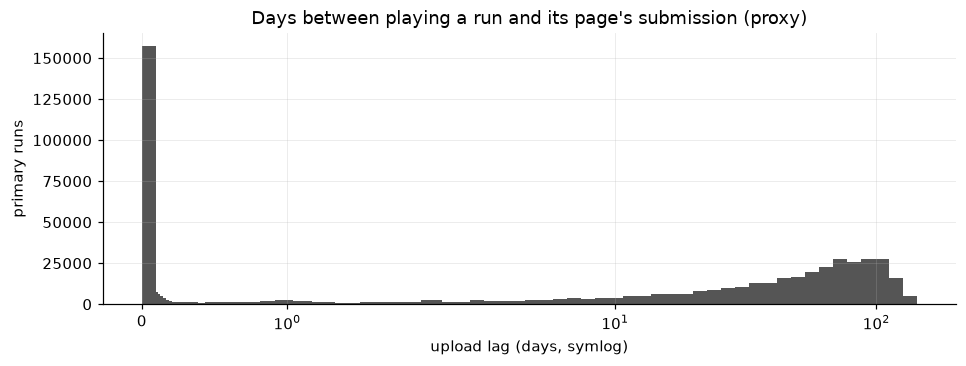

In [53]:
sub = runs.groupby("source_page").start_time.transform(lambda s: s.quantile(0.99))
lag_days = ((sub - runs.start_time).dt.total_seconds() / 86400).clip(lower=0)
p_lag = lag_days[runs.primary]
print("upload lag (days), primary runs:")
print(p_lag.quantile([0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_string())
for d in (7, 30, 90):
    print(f"uploaded more than {d:>2} days after being played: {(p_lag > d).mean():.1%}")
print("median lag by uploader group (days):",
      p_lag.groupby(runs.loc[runs.primary, "uploader_tag"].notna()).median()
      .rename({True: "tagged", False: "untagged"}).round(1).to_dict())

fig, ax = plt.subplots(figsize=(10, 3.2))
bins = np.concatenate([[0], np.logspace(-1, np.log10(max(p_lag.max(), 1) + 1), 60)])
ax.hist(p_lag, bins=bins, color="#555")
ax.set(xscale="symlog", xlabel="upload lag (days, symlog)", ylabel="primary runs",
       title="Days between playing a run and its page's submission (proxy)")
plt.show()

### Runs per build

Raw records, distinct runs (co-op copies merged on `run_key`), and **primary** runs (solo,
clean). The dashed line is a working threshold for "enough runs to use a build on its own".
`MIN_RUNS` is a placeholder until section 7 gives a power-based number.

,branch,records,runs,primary,primary_finished,first_play,last_play,release,thin
build_id,,,,,,,,,
v0.98.0,unknown,3447,3033,2249,2051,2026-03-05 17:53:15+00:00,2026-07-22 15:10:26+00:00,NaT,False
v0.98.1,stable,7638,6244,4904,4411,2026-03-05 18:09:44+00:00,2026-06-27 09:43:52+00:00,2026-03-05,False
v0.98.2,stable,24467,19135,15004,13321,2026-03-05 19:53:30+00:00,2026-07-09 18:48:21+00:00,2026-03-06,False
v0.98.3,stable,42470,32827,25433,22273,2026-03-05 20:46:58+00:00,2026-07-18 16:04:30+00:00,2026-03-10,False
v0.99.0,beta,356,321,293,266,2026-03-11 22:27:06+00:00,2026-07-11 18:11:59+00:00,2026-03-12,True
v0.99.1,stable,118769,88984,66236,56353,2026-03-06 03:03:57+00:00,2026-07-23 20:03:37+00:00,2026-03-17,False
v0.100.0,beta,8162,6797,5832,5112,2026-03-13 16:59:48+00:00,2026-07-25 16:29:57+00:00,2026-03-19,False
v0.101.0,beta,10859,8797,7271,6418,2026-03-08 03:21:50+00:00,2026-06-28 18:35:58+00:00,2026-03-26,False
v0.102.0,beta,13581,10648,8539,7520,2026-03-06 03:14:50+00:00,2026-06-14 19:33:08+00:00,2026-04-02,False


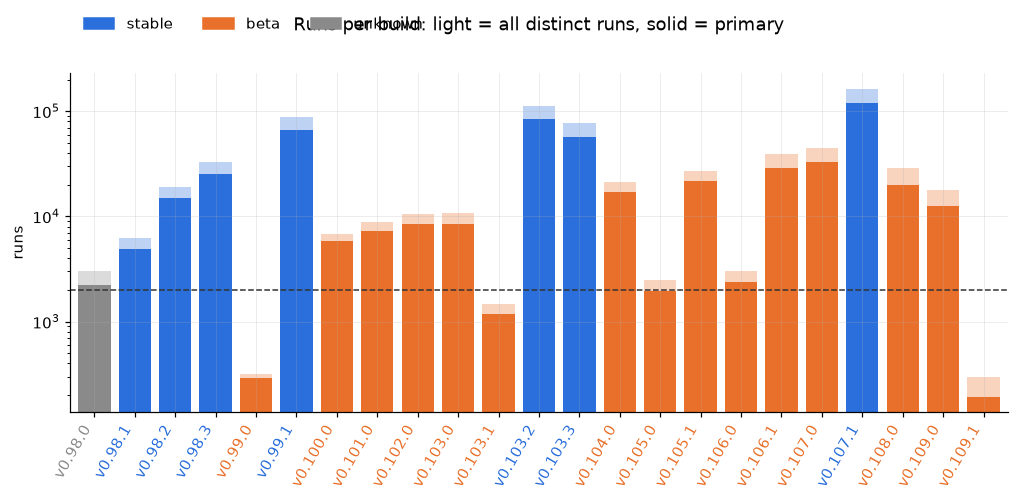

In [54]:
MIN_RUNS = 2000

per_build = (runs.groupby("build_id")
             .agg(records=("run_hash", "size"), runs=("run_key", "nunique"),
                  primary=("primary", "sum"),
                  primary_finished=("primary", lambda s: (s & ~runs.loc[s.index, "was_abandoned"]).sum()),
                  first_play=("start_time", "min"), last_play=("start_time", "max"))
             .reindex(BUILD_ORDER))
per_build.insert(0, "branch", per_build.index.map(lambda b: BRANCH.get(b, "not in builds.csv")))
per_build["release"] = per_build.index.map(RELEASE)
per_build["thin"] = per_build.primary < MIN_RUNS
display(per_build)

x = np.arange(len(per_build))
colors = [BRANCH_COLOR[b] for b in per_build.branch]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x, per_build.runs, color=colors, alpha=0.3, width=0.8)
ax.bar(x, per_build.primary, color=colors, width=0.8)
ax.axhline(MIN_RUNS, color="#333", ls="--", lw=1)
ax.set_yscale("log")
build_axis(ax)
ax.set(ylabel="runs", title="Runs per build: light = all distinct runs, solid = primary")
shown = ["stable", "beta", "unknown"]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=BRANCH_COLOR[c]) for c in shown], shown,
          frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.08))
ax.set_title(ax.get_title(), pad=28)
plt.show()

### Play date × build

One row per build, one column per day; color = runs that day (log scale). Ticks mark each
build's release date from `builds.csv`. Things to look for:

- **Adoption speed**: how quickly players leave a stable build once the next one ships.
  A slow move means pre and post periods overlap in calendar time. That helps DiD, since
  both sides see the same calendar, but it also means player learning and patch timing
  mix together.
- **Beta and stable side by side**: overlapping rows on the same days are what the
  staggered-rollout design needs.
- **Runs dated before their build's release**: should be none beyond a day of time-zone
  slop. More means a wrong release date, a clock problem, or a build that sat on the other
  branch first (v0.107.1 was on beta before its stable date, per the note in `builds.csv`).

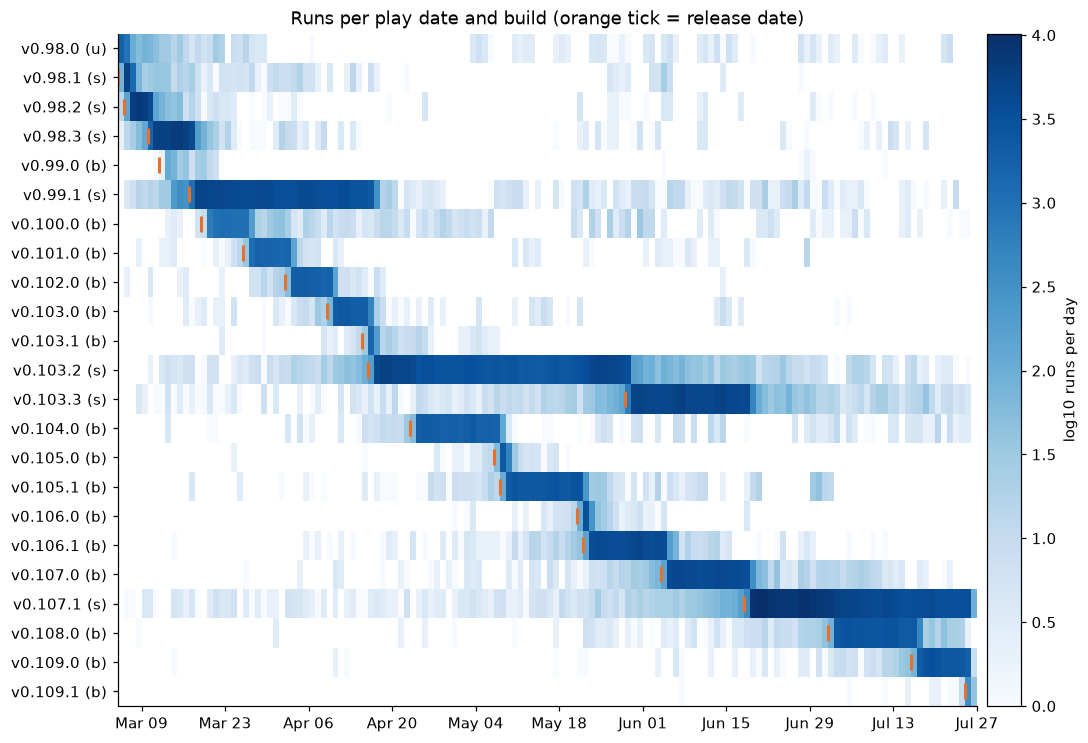

runs dated before their build's release date: 5566 (1 day early can be time zones; more is worth a look)


,count,min,50%,max
build_id,,,,
v0.100.0,13.0,1.0,4.0,6.0
v0.101.0,35.0,1.0,2.0,18.0
v0.102.0,82.0,1.0,3.0,27.0
v0.103.0,109.0,1.0,3.0,30.0
v0.103.1,33.0,1.0,3.0,24.0
v0.103.2,526.0,1.0,5.0,37.0
v0.103.3,843.0,1.0,6.0,82.0
v0.104.0,114.0,1.0,4.0,41.0
v0.105.0,40.0,1.0,2.0,44.0


In [55]:
grid = (runs[runs.released].pivot_table(index="build_id", columns="play_date", values="run_hash",
                         aggfunc="size", fill_value=0)
        .reindex(BUILD_ORDER))
fig, ax = plt.subplots(figsize=(12, 0.28 * len(grid) + 1.5))
days = grid.columns
im = ax.pcolormesh(mdates.date2num(days.append(pd.DatetimeIndex([days[-1] + pd.Timedelta("1D")]))),
                   np.arange(len(grid) + 1), np.log10(grid.where(grid > 0)),
                   cmap="Blues", shading="flat")
for i, b in enumerate(grid.index):
    if pd.notna(RELEASE.get(b)):
        ax.plot(mdates.date2num(RELEASE[b]), i + 0.5, marker="|", color="#e8702a", ms=10, mew=2)
ax.set_yticks(np.arange(len(grid)) + 0.5, [f"{b} ({BRANCH.get(b, '?')[:1]})" for b in grid.index])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.grid(False)
fig.colorbar(im, ax=ax, label="log10 runs per day", pad=0.01)
ax.set_title("Runs per play date and build (orange tick = release date)")
plt.show()

days_early = (runs.build_id.map(RELEASE) - runs.play_date).dt.days
early = runs.assign(days_early=days_early)[days_early > 0]   # = runs.before_release
print("runs dated before their build's release date:", len(early),
      "(1 day early can be time zones; more is worth a look)")
if len(early):
    display(early.groupby("build_id").days_early.describe()[["count", "min", "50%", "max"]])

## 3. Filters

The funnel from all records to the primary population, then each flag's share by build.
Things to look for: any filter that removes a lot more in some builds than others. Those
builds' primary samples are then a different population, not just a smaller one. Custom
runs, for example, only exist as a game mode from v0.107.1.

In [56]:
d = runs.drop_duplicates("run_key")
steps = [
    ("all records", runs),
    ("distinct runs (co-op copies merged)", d),
    ("solo", d[d.solo]),
    ("+ no modifiers", d[d.solo & (d.n_modifiers == 0)]),
    ("+ no mod markers", d[d.solo & d.clean]),
    ("+ released build", d[d.solo & d.clean & d.released]),
    ("+ not dated before release", d[d.solo & d.clean & d.released & ~d.before_release]),
    ("+ starts at Neow (primary)", d[d.primary]),
    ("+ not abandoned (win analyses)", d[d.primary & ~d.was_abandoned]),
]
funnel = pd.DataFrame([(k, len(v)) for k, v in steps], columns=["step", "runs"])
funnel["share of distinct"] = funnel.runs / len(d)
display(funnel.style.format({"runs": "{:,}", "share of distinct": "{:.1%}"}))

print("mod markers (records):")
print(runs[MOD_COLS].sum().to_string())

,step,runs,share of distinct
0,all records,"947,885",130.3%
1,distinct runs (co-op copies merged),"727,714",100.0%
2,solo,"577,092",79.3%
3,+ no modifiers,"558,325",76.7%
4,+ no mod markers,"550,245",75.6%
5,+ released build,"549,941",75.6%
6,+ not dated before release,"547,329",75.2%
7,+ starts at Neow (primary),"544,623",74.8%
8,+ not abandoned (win analyses),"439,399",60.4%


mod markers (records):
mod_save_dict    13164
mod_acts          1008
mod_character      824
mod_modifier      5233
mod_card          2532


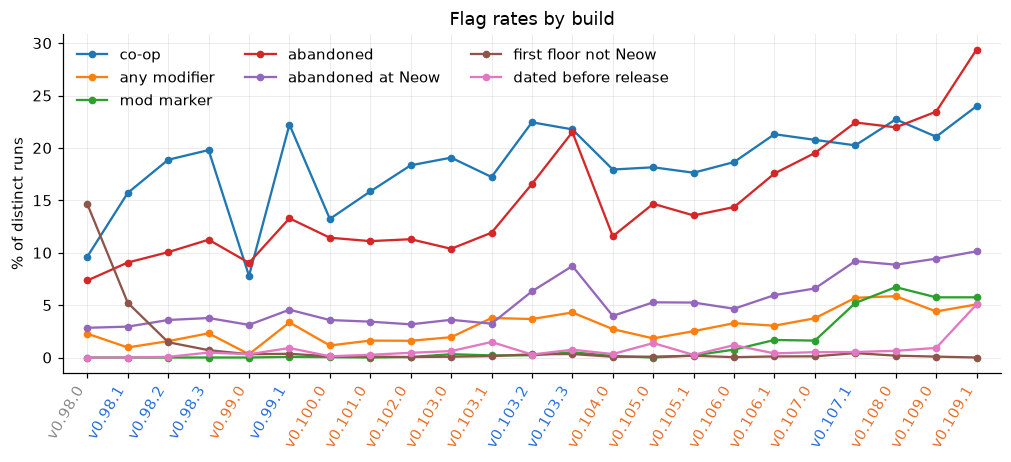

In [57]:
flags = {
    "co-op": ~d.solo,
    "any modifier": d.n_modifiers > 0,
    "mod marker": d.modded,
    "abandoned": d.was_abandoned,
    "abandoned at Neow": d.abandoned_at_neow,
    "first floor not Neow": ~d.first_floor_neow,
    "dated before release": d.before_release,
}
rates = pd.DataFrame(flags).groupby(d.build_id).mean().reindex(BUILD_ORDER)
fig, ax = plt.subplots(figsize=(11, 4))
for c in rates:
    ax.plot(range(len(rates)), rates[c] * 100, marker="o", label=c)
build_axis(ax)
ax.set(ylabel="% of distinct runs", title="Flag rates by build")
ax.legend(frameon=False, ncol=3)
plt.show()

## 4. Plausibility

The data has no "cheated" flag, so look for runs that can't be real: wins that are too
fast, wins that didn't reach act 3, and outliers in gold, HP, or deck size. Only
**primary** runs here (mods and custom runs are excluded anyway).

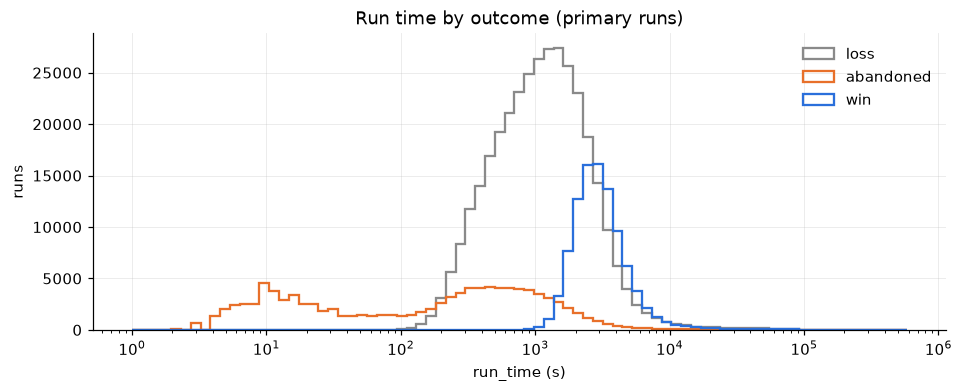

count     97082.0
mean       3845.0
std        7364.0
min         463.0
0.1%        938.0
1%         1284.0
5%         1626.0
50%        2898.0
max      508881.0


In [58]:
p = runs[runs.primary].copy()
p["outcome"] = np.select([p.win, p.was_abandoned], ["win", "abandoned"], "loss")
bins = np.logspace(0, np.log10(max(p.run_time_s.max(), 10)), 80)
fig, ax = plt.subplots(figsize=(10, 3.5))
for o, c in [("loss", "#8a8a8a"), ("abandoned", "#e8702a"), ("win", "#2a6fdb")]:
    ax.hist(p.loc[p.outcome == o, "run_time_s"].clip(lower=1), bins=bins, histtype="step",
            lw=1.5, color=c, label=o)
ax.set_xscale("log")
ax.set(xlabel="run_time (s)", ylabel="runs", title="Run time by outcome (primary runs)")
ax.legend(frameon=False)
plt.show()

wins = p[p.win]
print(wins.run_time_s.describe(percentiles=[0.001, 0.01, 0.05, 0.5]).round(0).to_string())

In [59]:
FAST_WIN_S = 15 * 60                 # adjust after looking at the histogram
odd = pd.DataFrame({
    f"win under {FAST_WIN_S//60} min": wins.run_time_s < FAST_WIN_S,
    "win before act 3": wins.acts_reached < 3,
    "win, zero combat turns": wins.total_turns == 0,
})
print(odd.sum().to_string())
display(wins[odd.any(axis=1)][["build_id", "character", "ascension", "run_time_s", "acts_reached",
                               "floors_reached", "total_turns", "deck_size", "n_relics",
                               "final_gold", "final_max_hp", "uploader_tag"]].head(30))

win under 15 min          69
win before act 3           0
win, zero combat turns     0


,build_id,character,ascension,run_time_s,acts_reached,floors_reached,total_turns,deck_size,n_relics,final_gold,final_max_hp,uploader_tag
65299,v0.103.2,REGENT,0,718,3,48,39,9,39,7355,95,NaN
160253,v0.102.0,REGENT,10,874,3,49,76,26,17,133,82,NaN
194174,v0.103.3,IRONCLAD,1,868,3,48,59,13,13,76,95,NaN
228603,v0.99.1,DEFECT,0,497,3,48,38,8,16,459,87,NaN
244786,v0.103.2,REGENT,7,895,3,48,78,22,12,108,83,NaN
244827,v0.103.2,IRONCLAD,5,734,3,48,64,22,13,25,67,NaN
244831,v0.103.2,IRONCLAD,4,794,3,48,71,15,11,104,60,NaN
244834,v0.103.2,IRONCLAD,3,820,3,48,72,20,16,31,78,NaN
244873,v0.103.2,REGENT,5,856,3,48,74,27,13,108,107,NaN
244878,v0.103.2,REGENT,4,758,3,48,90,27,12,28,76,NaN


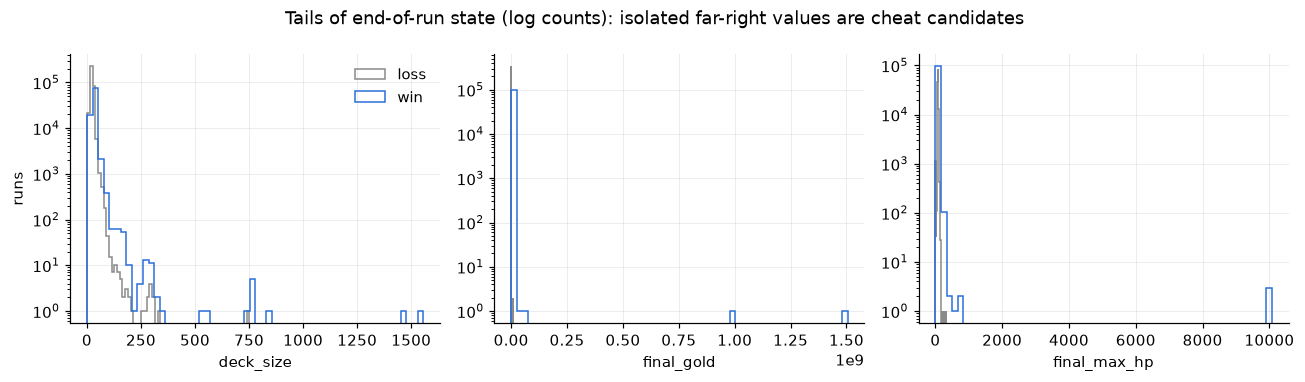

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ["deck_size", "final_gold", "final_max_hp"]):
    for o, c in [("loss", "#8a8a8a"), ("win", "#2a6fdb")]:
        ax.hist(p.loc[p.outcome == o, col].dropna(), bins=60, histtype="step", color=c, label=o)
    ax.set_yscale("log")
    ax.set(xlabel=col)
axes[0].set_ylabel("runs")
axes[0].legend(frameon=False)
fig.suptitle("Tails of end-of-run state (log counts): isolated far-right values are cheat candidates")
fig.tight_layout()
plt.show()

## 5. Population mix

If the mix of characters or ascensions shifts between builds, raw before/after
comparisons pick that shift up. The DiD designs are built to handle it, but it's worth
seeing how big the shifts are. Same for who uploads: solo runs all have `player_id: 1`,
so individual uploaders can't be tracked. The one handle is the `_sts` field, which marks
runs uploaded by the SlayTheStats mod (see the note after the weekly panel).

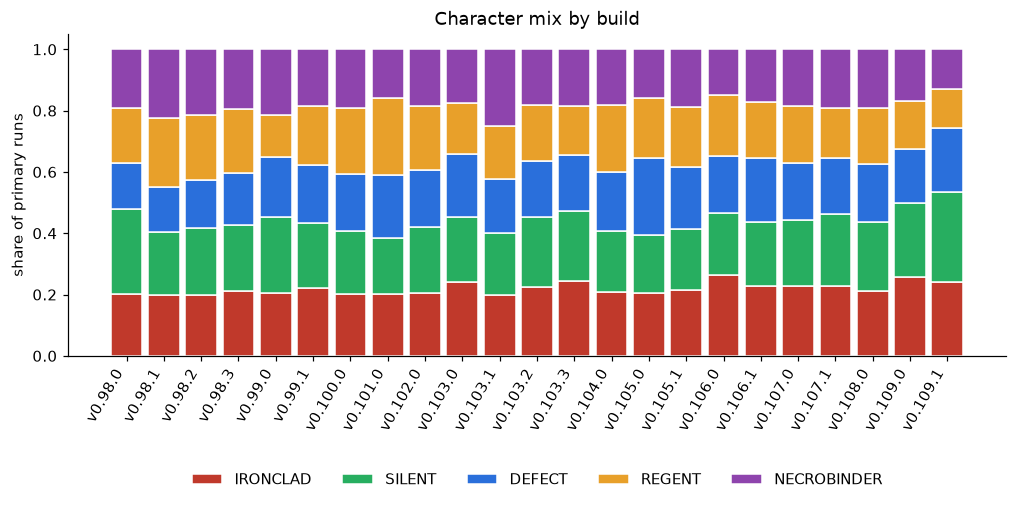

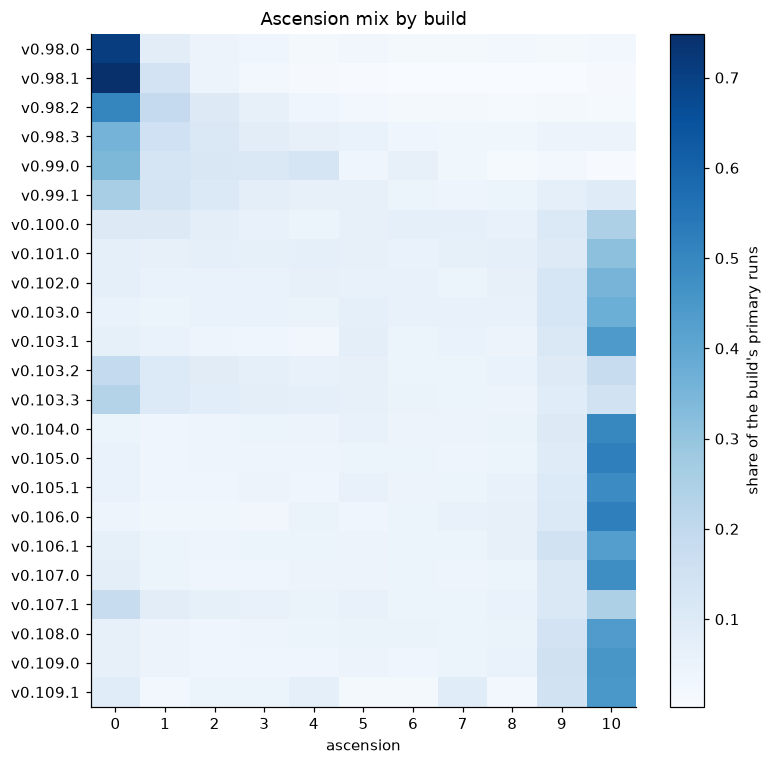

In [61]:
pf = p[~p.was_abandoned]
mix = pd.crosstab(p.build_id, p.character, normalize="index").reindex(BUILD_ORDER)
mix = mix[[c for c in CHARS if c in mix] + [c for c in mix if c not in CHARS]]
fig, ax = plt.subplots(figsize=(11, 3.8))
bottom = np.zeros(len(mix))
for c in mix:
    ax.bar(range(len(mix)), mix[c], bottom=bottom, color=CHAR_COLOR.get(c, "#ccc"),
           label=c, width=0.85, edgecolor="white", linewidth=1)
    bottom += mix[c].to_numpy()
ax.set_xticks(range(len(mix)), mix.index, rotation=60, ha="right")
ax.set(ylabel="share of primary runs", title="Character mix by build")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.32))
ax.grid(False)
plt.show()

asc = pd.crosstab(p.build_id, p.ascension, normalize="index").reindex(BUILD_ORDER)
fig, ax = plt.subplots(figsize=(8, 0.28 * len(asc) + 1.5))
im = ax.imshow(asc, aspect="auto", cmap="Blues")
ax.set_xticks(range(asc.shape[1]), asc.columns)
ax.set_yticks(range(len(asc)), asc.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="share of the build's primary runs")
ax.set(xlabel="ascension", title="Ascension mix by build")
plt.show()

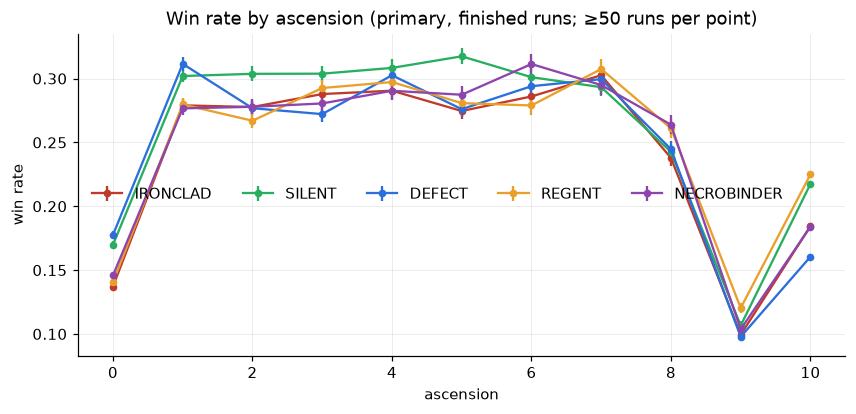

In [62]:
wr = pf.groupby(["character", "ascension"]).win.agg(["sum", "size"])
wr = wr[wr["size"] >= 50]
fig, ax = plt.subplots(figsize=(9, 3.8))
for c in CHARS:
    if c not in wr.index.get_level_values(0):
        continue
    w = wr.loc[c]
    ax.errorbar(w.index, w["sum"] / w["size"], yerr=binom_se(w["sum"], w["size"]),
                marker="o", color=CHAR_COLOR[c], label=c, capsize=0)
ax.set(xlabel="ascension", ylabel="win rate", title="Win rate by ascension (primary, finished runs; ≥50 runs per point)")
ax.legend(frameon=False, ncol=5)
plt.show()

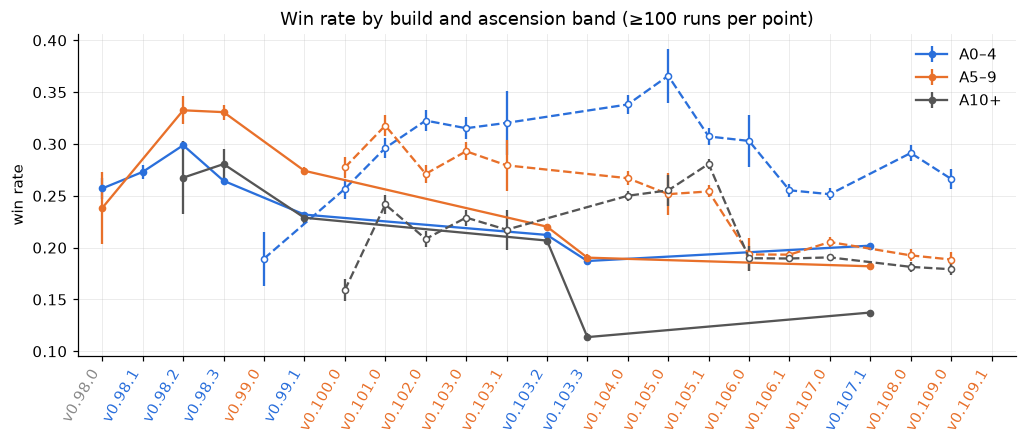

In [63]:
# Win rate by build within ascension bands: meta and patch drift before any card-level work
pf2 = pf.assign(asc_band=pd.cut(pf.ascension, [-1, 4, 9, 20], labels=["A0–4", "A5–9", "A10+"]))
g = pf2.groupby(["asc_band", "build_id"], observed=True).win.agg(["sum", "size"])
fig, ax = plt.subplots(figsize=(11, 3.8))
for band, color in zip(["A0–4", "A5–9", "A10+"], ["#2a6fdb", "#e8702a", "#555"]):
    if band not in g.index.get_level_values(0):
        continue
    w = g.loc[band].rename(columns={"sum": "k", "size": "n"})
    branch_errorbar(ax, w, color, band, min_n=100)
build_axis(ax)
ax.set(ylabel="win rate", title="Win rate by build and ascension band (≥100 runs per point)")
ax.legend(frameon=False)
plt.show()

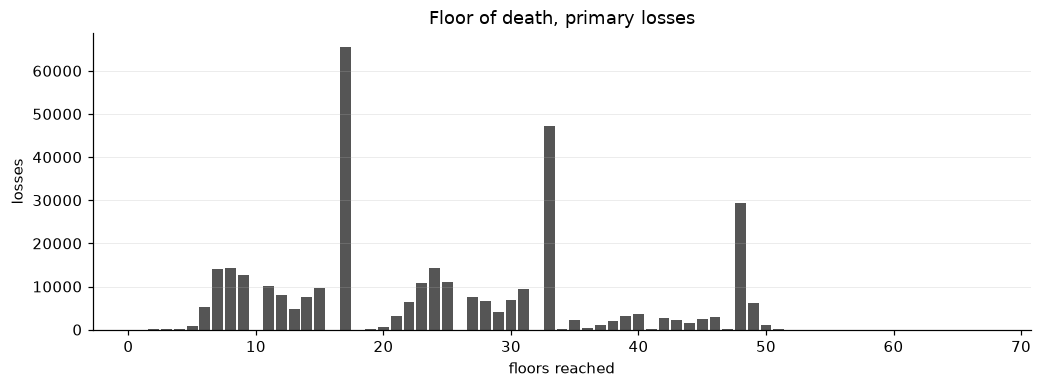

top killers:
killed_by_encounter
KNOWLEDGE_DEMON_BOSS     18388
DECIMILLIPEDE_ELITE      17510
KAISER_CRAB_BOSS         17026
BYGONE_EFFIGY_ELITE      13389
THE_INSATIABLE_BOSS      13337
TEST_SUBJECT_BOSS        13208
INFESTED_PRISMS_ELITE    12920
WATERFALL_GIANT_BOSS     12704
PHROG_PARASITE_ELITE     12464
ENTOMANCER_ELITE         12076
VANTOM_BOSS              11631
QUEEN_BOSS               11259


In [64]:
# Where runs end: floor reached for primary losses (a preview of the survival analysis)
losses = pf[~pf.win]
fig, ax = plt.subplots(figsize=(11, 3.5))
cnt = losses.floors_reached.value_counts().sort_index()
ax.bar(cnt.index, cnt.values, width=0.85, color="#555")
ax.set(xlabel="floors reached", ylabel="losses", title="Floor of death, primary losses")
ax.grid(axis="x", visible=False)
plt.show()
print("top killers:")
print(losses.killed_by_encounter.fillna("event: " + losses.killed_by_event.fillna("?"))
      .value_counts().head(12).to_string())

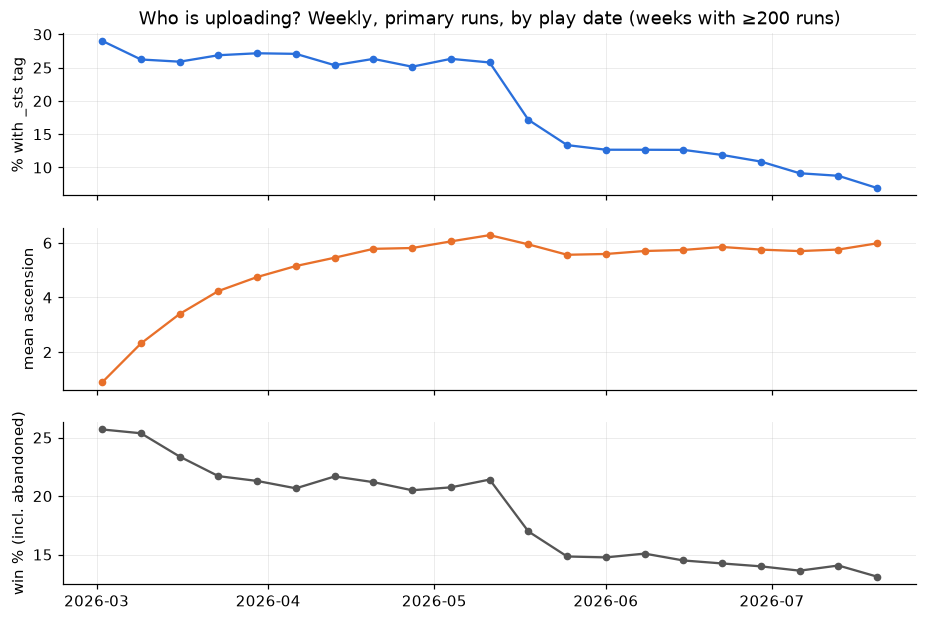

In [65]:
# Uploader mix over time (weekly, by play date)
wk = p.assign(week=p.play_date.dt.to_period("W").dt.start_time)
weekly = wk.groupby("week").agg(runs=("run_hash", "size"),
                                tagged=("uploader_tag", lambda s: s.notna().mean()),
                                mean_asc=("ascension", "mean"),
                                win=("win", "mean"))
weekly = weekly[weekly.runs >= 200]
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
axes[0].plot(weekly.index, weekly.tagged * 100, marker="o", color="#2a6fdb")
axes[0].set_ylabel("% with _sts tag")
axes[1].plot(weekly.index, weekly.mean_asc, marker="o", color="#e8702a")
axes[1].set_ylabel("mean ascension")
axes[2].plot(weekly.index, weekly.win * 100, marker="o", color="#555")
axes[2].set_ylabel("win % (incl. abandoned)")
axes[0].set_title("Who is uploading? Weekly, primary runs, by play date (weeks with ≥200 runs)")
plt.show()

### What the `_sts` tag is, and what the weekly panel can and can't show

`_sts` (`"slay-the-stats/vX"`) is a provenance stamp added by the **SlayTheStats** mod to every
run it uploads to Spire Codex (`SlayTheStats/Community/RunSubmitter.cs` in
github.com/giulianoconte/slay-the-stats; the field isn't in its README). Uploading is opt-in and
arrived together with the stamp in **v1.2.0, released 2026-06-19**. So every run the mod uploads
is tagged, and nothing tagged was submitted before June 19. When enabled, the mod uploads the
player's **whole local run history, oldest first** (directory order, no sort), **at most 200
runs per game launch**. That's why tagged runs appear on every build back to March.

What follows for the plots:

- **Tagged share by play date is not a population measure.** The snapshot holds submissions up
  to about July 19, so it contains roughly a month of mod uploads, with many backlogs only
  partly drained, oldest runs first. Early play dates are over-represented among tagged runs,
  and the rest of the export will add tagged runs from later dates. The mid-May drop in tagged
  share is most likely this.
- **The overall win-rate step can follow from the same thing** if tagged players win more
  than untagged ones: the overall rate moves with the mix. The panel below splits every rate by
  group. If each group's win rate among finished runs is roughly flat through May, the step is
  mix, not the game. The abandon panel separates quitting from losing.
- **The cleanest check is inside one build.** Stable v0.103.2 was the main build from mid-April
  to May 29, with no card changes, so a drop in its own weekly win rate can't be a patch. That
  check is two cells down.
- The export-page figure shows where tagged submissions start in the export (June 19 onward).


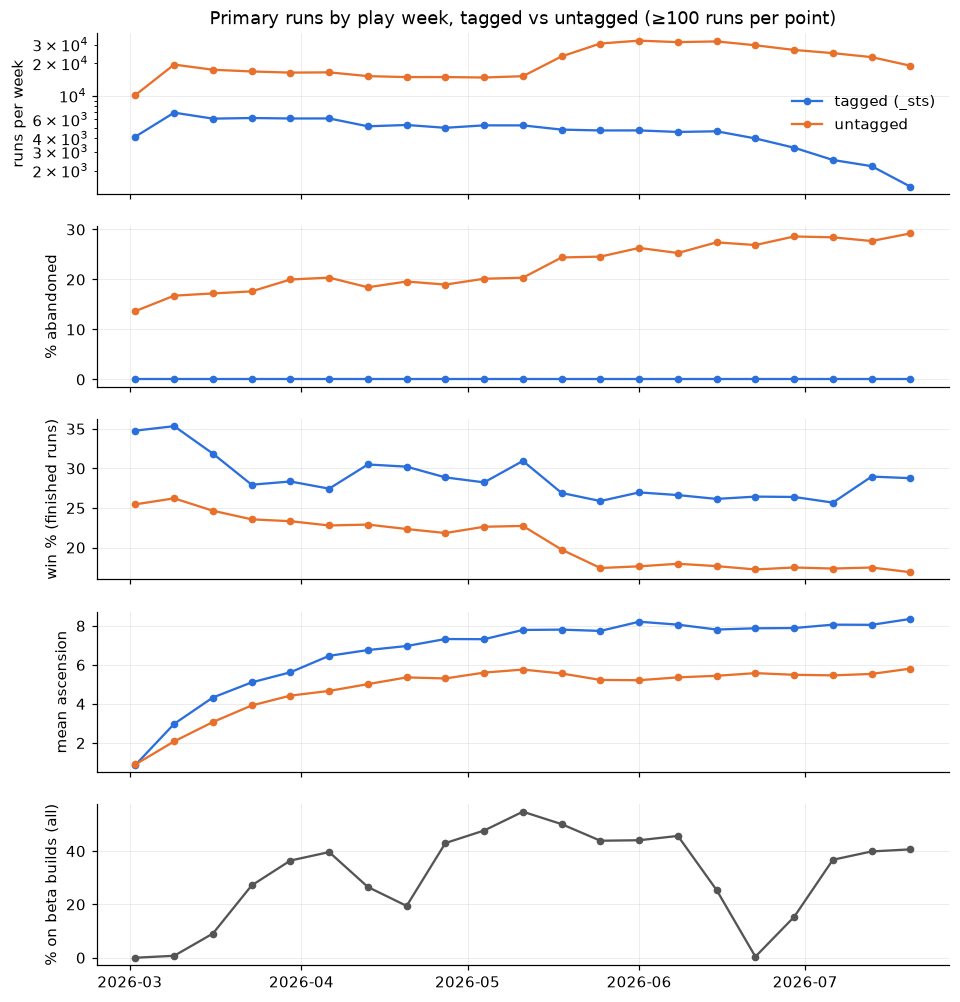

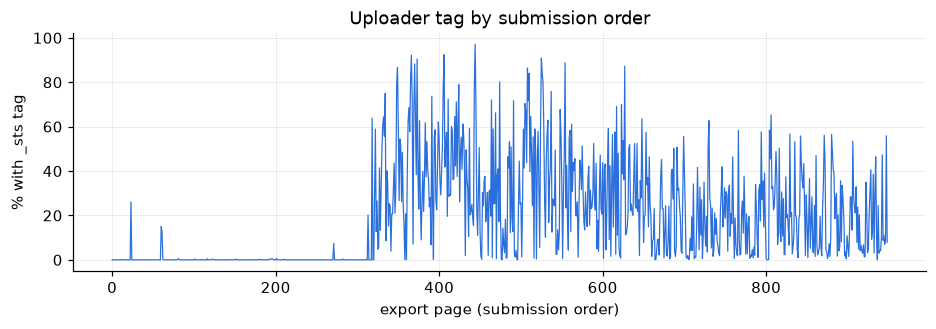

In [66]:
MIN_WEEK = 100
q = runs[runs.primary].assign(week=lambda x: x.play_date.dt.to_period("W").dt.start_time,
                              tagged=lambda x: x.uploader_tag.notna(),
                              beta=lambda x: x.branch.eq("beta"))
fin = q[~q.was_abandoned]
g = q.groupby(["week", "tagged"]).agg(runs=("run_hash", "size"),
                                      abandoned=("was_abandoned", "mean"),
                                      asc=("ascension", "mean"))
g["win_finished"] = fin.groupby(["week", "tagged"]).win.mean()
g = g[g.runs >= MIN_WEEK]
beta_share = q.groupby("week").beta.mean()

GROUP = {True: ("tagged (_sts)", "#2a6fdb"), False: ("untagged", "#e8702a")}
fig, axes = plt.subplots(5, 1, figsize=(10, 11), sharex=True)
for tagged, (name, color) in GROUP.items():
    if tagged not in g.index.get_level_values(1):
        continue
    s = g.xs(tagged, level="tagged")
    axes[0].plot(s.index, s.runs, marker="o", color=color, label=name)
    axes[1].plot(s.index, s.abandoned * 100, marker="o", color=color)
    axes[2].plot(s.index, s.win_finished * 100, marker="o", color=color)
    axes[3].plot(s.index, s.asc, marker="o", color=color)
axes[4].plot(beta_share.index, beta_share * 100, marker="o", color="#555")
for ax, lab in zip(axes, ["runs per week", "% abandoned", "win % (finished runs)",
                          "mean ascension", "% on beta builds (all)"]):
    ax.set_ylabel(lab)
axes[0].set_yscale("log")
axes[0].legend(frameon=False)
axes[0].set_title(f"Primary runs by play week, tagged vs untagged (≥{MIN_WEEK} runs per point)")
plt.show()

pg = runs.groupby("source_page").uploader_tag.apply(lambda s: s.notna().mean())
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(pg.index, pg * 100, lw=0.8, color="#2a6fdb")
ax.set(xlabel="export page (submission order)", ylabel="% with _sts tag",
       title="Uploader tag by submission order")
plt.show()

#### Inside one build: v0.103.2 by play week

Same game and card versions throughout, so any week-to-week change is the population or
chance, not a patch. Win rate among finished primary runs, split by uploader group, with
mean ascension: if ascension climbs while win rate falls, players moving up ascension explains
at least part of the decline.

,runs untagged,runs tagged,win untagged,win tagged,win all,asc untagged,asc tagged
week,,,,,,,
2026-04-13 00:00:00,"5,249","2,178",0.229,0.321,0.256,5.03,6.85
2026-04-20 00:00:00,"9,936","3,865",0.215,0.299,0.239,4.96,6.68
2026-04-27 00:00:00,"7,432","2,158",0.208,0.250,0.217,4.11,6.18
2026-05-04 00:00:00,"6,589","2,101",0.202,0.252,0.214,4.26,5.81
2026-05-11 00:00:00,"6,042","1,629",0.193,0.273,0.210,4.51,5.98
2026-05-18 00:00:00,"9,305","1,464",0.180,0.222,0.186,4.03,6.09
2026-05-25 00:00:00,"9,343","1,091",0.166,0.236,0.173,3.98,5.95
2026-06-01 00:00:00,265,32,0.272,0.312,0.276,3.02,4.44


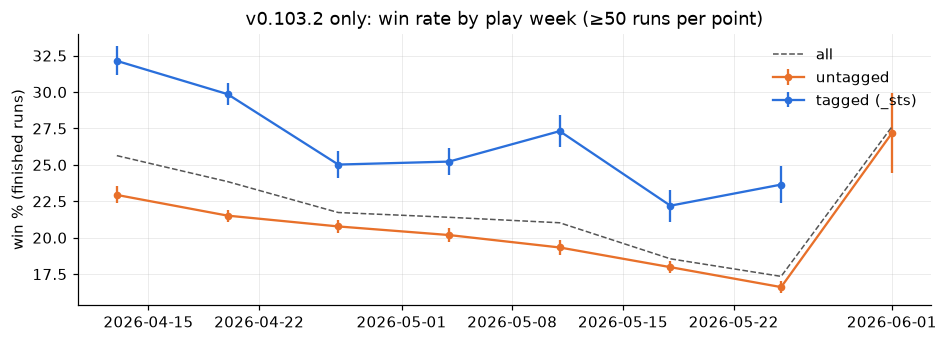

In [67]:
WITHIN = "v0.103.2"
s = runs[runs.primary & runs.build_id.eq(WITHIN) & ~runs.was_abandoned]
s = s.assign(week=s.play_date.dt.to_period("W").dt.start_time, tagged=s.uploader_tag.notna())
w = (s.groupby(["week", "tagged"])
     .agg(runs=("win", "size"), wins=("win", "sum"), asc=("ascension", "mean"))
     .unstack("tagged"))
w = w[w["runs"].fillna(0).sum(axis=1) >= 200]
table = pd.DataFrame({
    "runs untagged": w["runs"].get(False), "runs tagged": w["runs"].get(True),
    "win untagged": w["wins"].get(False) / w["runs"].get(False),
    "win tagged": w["wins"].get(True) / w["runs"].get(True),
    "win all": w["wins"].sum(axis=1) / w["runs"].sum(axis=1),
    "asc untagged": w["asc"].get(False), "asc tagged": w["asc"].get(True),
})
display(table.style.format({c: "{:.3f}" for c in table if c.startswith("win")} |
                           {c: "{:,.0f}" for c in table if c.startswith("runs")} |
                           {c: "{:.2f}" for c in table if c.startswith("asc")}))

fig, ax = plt.subplots(figsize=(10, 3.2))
for col, color, lab in [("untagged", "#e8702a", "untagged"), ("tagged", "#2a6fdb", "tagged (_sts)")]:
    k, n = w["wins"].get(col == "tagged"), w["runs"].get(col == "tagged")
    if k is None:
        continue
    ok = n >= 50
    ax.errorbar(n.index[ok], (k / n)[ok] * 100, yerr=binom_se(k, n)[ok] * 100, marker="o",
                color=color, label=lab, capsize=0)
ax.plot(table.index, table["win all"] * 100, color="#555", lw=1, ls="--", label="all")
ax.set(ylabel="win % (finished runs)", title=f"{WITHIN} only: win rate by play week (≥50 runs per point)")
ax.legend(frameon=False)
plt.show()

## 6. Offers

Checks on what the pick-rate design assumes:

- **List sizes.** Card rewards should be 3 cards (4 with Lasting Candy). Longer lists are
  merged reward screens (run_schema.md, ~2.5% of combat lists), and their share sets
  how much the screen-splitting decision matters.
- **Skip rate** (no card picked from the list) by source and build. A patch-wide shift in
  skipping moves every card's pick rate at once. Unchanged cards control for that in the
  DiD, but it's worth knowing how big it is.
- **Upgraded offers.** Their share rises with act, so upgrade status has to be a control.

list_len,1,2,3,4,5,6,7,8
source,,,,,,,,
ancient,28.44,31.01,22.26,0.08,0.07,12.16,0.04,0.04
boss,0.00,0.00,97.52,1.89,0.03,0.53,0.00,0.01
combat,0.00,0.00,96.56,1.25,0.02,2.09,0.01,0.04
elite,0.00,0.00,96.08,1.50,0.01,2.32,0.00,0.05
event,0.00,0.00,67.50,2.19,0.02,11.53,0.00,0.00
event_combat,0.00,0.00,96.40,1.29,0.02,2.21,0.01,0.04
rest_site,0.00,0.00,98.16,1.11,0.03,0.57,0.02,0.01
shop,0.03,0.13,0.73,3.73,17.39,39.96,37.27,0.00
treasure,0.00,0.00,81.36,0.00,1.69,5.08,0.00,0.00


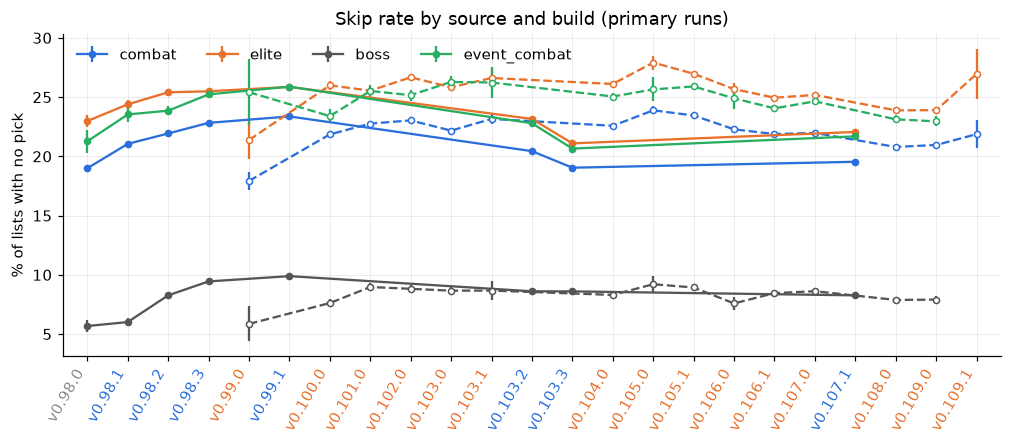

In [68]:
CORE = ["combat", "elite", "boss", "event_combat"]
L = lists[lists.solo & lists.clean & ~lists.before_release & lists.neow_start]
size = L.pivot_table(index="source", columns="list_len", values="n", aggfunc="sum", fill_value=0)
display((size.div(size.sum(axis=1), axis=0) * 100).round(2).loc[:, :8])

lc = L[L.source.isin(CORE)]
skip = (lc.assign(skipped=lc.n_picked == 0)
        .groupby(["source", "build_id"])
        .apply(lambda g: pd.Series({"k": g.loc[g.skipped, "n"].sum(), "n": g.n.sum()}),
               include_groups=False))
fig, ax = plt.subplots(figsize=(11, 3.8))
for src, color in zip(CORE, ["#2a6fdb", "#e8702a", "#555", "#27ae60"]):
    if src not in skip.index.get_level_values(0):
        continue
    branch_errorbar(ax, skip.loc[src], color, src, min_n=200, scale=100)
build_axis(ax)
ax.set(ylabel="% of lists with no pick", title="Skip rate by source and build (primary runs)")
ax.legend(frameon=False, ncol=4)
plt.show()

In [69]:
O = offers[offers.solo & offers.clean & ~offers.before_release & offers.neow_start
           & offers.source.isin(CORE)]
up = O.groupby(["act", "source", "upgraded"]).n.sum().unstack("upgraded", fill_value=0)
up["% upgraded"] = (up[True] / up.sum(axis=1) * 100).round(1)
display(up["% upgraded"].unstack("source"))

ench = O.groupby("build_id").apply(lambda g: g.loc[g.enchanted, "n"].sum() / g.n.sum() * 100,
                                   include_groups=False).reindex(BUILD_ORDER)
print("% of offers enchanted, by build:")
print(ench.round(2).to_string())

source,boss,combat,elite,event_combat
act,,,,
1,1.8,4.0,1.7,2.7
2,3.9,21.4,20.5,21.2
3,41.2,42.0,38.0,41.3
4,NaN,59.0,12.2,44.4


% of offers enchanted, by build:
build_id
v0.98.0     1.37
v0.98.1     1.32
v0.98.2     1.39
v0.98.3     1.30
v0.99.0     1.23
v0.99.1     1.25
v0.100.0    1.33
v0.101.0    1.40
v0.102.0    1.32
v0.103.0    1.60
v0.103.1    1.49
v0.103.2    1.29
v0.103.3    1.27
v0.104.0    1.54
v0.105.0    2.37
v0.105.1    2.26
v0.106.0    2.07
v0.106.1    2.07
v0.107.0    2.12
v0.107.1    1.92
v0.108.0    2.09
v0.109.0    2.01
v0.109.1    1.90


## 7. Power

For the minimum result (pick-rate DiD per numeric tweak), each changed card needs enough
offers on both sides of its change. For a rough scale: with pick rate p ≈ 0.3 and n offers
on each side, the standard error of the difference is √(2·p(1−p)/n). That's about 2
percentage points at n = 1,000 and 0.65 at n = 10,000. A 5-point shift needs roughly
n ≳ 1,000 per side to show at 2.5σ, before the extra noise the DiD control adds.

Windows here are the simple stable-to-stable version: the stable builds before the change's
`stable_build` vs the stable builds from it up to the next major update. The beta windows
come later (treatment table, Phase 4). The 4 relabeled cards (Glow, Grave Warden, Shatter,
Tesla Coil) are left out of the tweak set, per the decision log.

47 numeric-tweak cards, 50 card × stable-window changes


,card_id,stable_build,n_pre,n_post,k_pre,k_post,p_pre,p_post,diff,se_diff
1,BELIEVE_IN_YOU,v0.103.2,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
7,FALLING_STAR,v0.103.2,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
19,MINION_STRIKE,v0.103.2,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
39,MINION_SACRIFICE,v0.107.1,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
6,ETERNAL_ARMOR,v0.103.2,36.0,58.0,3.0,17.0,0.083,0.293,0.210,0.075
25,SEEKER_STRIKE,v0.103.2,55.0,92.0,14.0,30.0,0.255,0.326,0.072,0.076
35,FASTEN,v0.107.1,110.0,86.0,58.0,49.0,0.527,0.570,0.042,0.072
15,I_AM_INVINCIBLE,v0.103.2,3932.0,4163.0,1173.0,1355.0,0.298,0.325,0.027,0.010
13,HEIRLOOM_HAMMER,v0.103.2,3964.0,4148.0,586.0,643.0,0.148,0.155,0.007,0.008
46,THE_SCYTHE,v0.107.1,3989.0,3340.0,1056.0,908.0,0.265,0.272,0.007,0.010


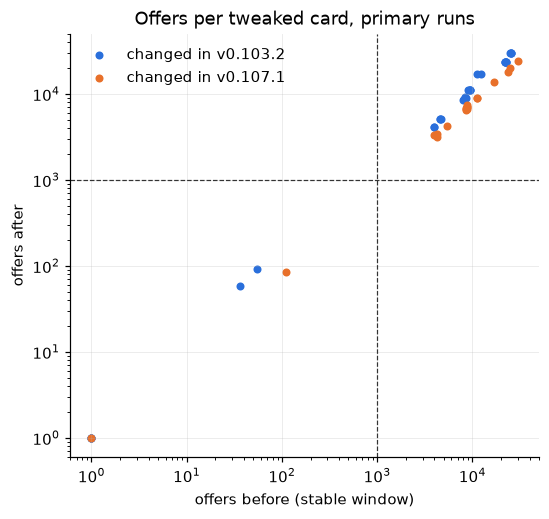

In [70]:
cc = pd.read_csv(ROOT / "reference" / "card_changes.csv")
RELABELED = {"GLOW", "GRAVE_WARDEN", "SHATTER", "TESLA_COIL"}
tw = (cc[(cc.change_kind == "tweak") & ~cc.card_id.isin(RELABELED)]
      .drop_duplicates(["card_id", "stable_build"])[["card_id", "beta_build", "stable_build"]])
print(tw.card_id.nunique(), "numeric-tweak cards,", len(tw), "card × stable-window changes")

STABLE_WINDOWS = {                     # post-window starts at the key build
    "v0.103.2": (["v0.98.1", "v0.98.2", "v0.98.3", "v0.99.1"], ["v0.103.2", "v0.103.3"]),
    "v0.107.1": (["v0.103.2", "v0.103.3"], ["v0.107.1"]),
}
by_build = O.groupby(["card_id", "build_id"]).agg(n=("n", "sum"))
by_build["k"] = O[O.picked].groupby(["card_id", "build_id"]).n.sum()
by_build = by_build.fillna(0)

seen_cards = set(by_build.index.get_level_values(0))
def window(card, bs):
    if card not in seen_cards:
        return pd.Series({"n": 0.0, "k": 0.0})
    return by_build.loc[card].reindex(bs).sum()

rows = []
for r in tw.itertuples():
    pre_b, post_b = STABLE_WINDOWS.get(r.stable_build, ([], []))
    pre, post = window(r.card_id, pre_b), window(r.card_id, post_b)
    rows.append((r.card_id, r.stable_build, pre.n, post.n, pre.k, post.k))
power = pd.DataFrame(rows, columns=["card_id", "stable_build", "n_pre", "n_post", "k_pre", "k_post"])
power["p_pre"] = power.k_pre / power.n_pre
power["p_post"] = power.k_post / power.n_post
power["diff"] = power.p_post - power.p_pre
power["se_diff"] = np.sqrt(power.p_pre * (1 - power.p_pre) / power.n_pre +
                           power.p_post * (1 - power.p_post) / power.n_post)
display(power.sort_values("n_pre").round(3).head(15))

fig, ax = plt.subplots(figsize=(5.5, 5))
for sb, color in zip(STABLE_WINDOWS, ["#2a6fdb", "#e8702a"]):
    s = power[power.stable_build == sb]
    ax.scatter(s.n_pre.clip(lower=1), s.n_post.clip(lower=1), s=18, color=color, label=f"changed in {sb}")
for v in (1000,):
    ax.axvline(v, color="#333", ls="--", lw=0.8)
    ax.axhline(v, color="#333", ls="--", lw=0.8)
ax.set(xscale="log", yscale="log", xlabel="offers before (stable window)",
       ylabel="offers after", title="Offers per tweaked card, primary runs")
ax.legend(frameon=False)
plt.show()

In [71]:
from scipy import stats

B = "v0.107.1"
G = O[O.build_id == B]
t = (G.assign(k=G.n.where(G.picked, 0))
       .groupby(["card_id", "tagged"])[["n", "k"]].sum().unstack("tagged"))
t = t[(t["n"] >= 200).all(axis=1)]
nt, nu = t["n"][True], t["n"][False]
pt, pu = t["k"][True] / nt, t["k"][False] / nu
p = (t["k"][True] + t["k"][False]) / (nt + nu)          # pooled rate, for the null SE
z = (pt - pu) / np.sqrt(p * (1 - p) * (1 / nt + 1 / nu))

print(f"{len(z)} cards; mean z {z.mean():+.2f}, sd of z {z.std():.2f}  (≈0 and ≈1 if alike)")
print("KS vs N(0,1):                 ", stats.kstest(z, "norm"))
print("KS after removing the offset: ", stats.kstest(z - z.mean(), "norm"))
chi2, dof = ((z - z.mean()) ** 2).sum(), len(z) - 1
print(f"spread: chi2 = {chi2:.0f} on {dof} dof, p = {stats.chi2.sf(chi2, dof):.2g}")

400 cards; mean z -0.54, sd of z 4.95  (≈0 and ≈1 if alike)
KS vs N(0,1):                  KstestResult(statistic=np.float64(0.38498072990129634), pvalue=np.float64(7.521580596209549e-54), statistic_location=np.float64(-1.9185718562062364), statistic_sign=np.int8(1))
KS after removing the offset:  KstestResult(statistic=np.float64(0.33175381680952687), pvalue=np.float64(9.785720343618901e-40), statistic_location=np.float64(-1.714198009338057), statistic_sign=np.int8(1))
spread: chi2 = 9769 on 399 dof, p = 0


### Runs dated before release: how concentrated?

Overall they're ~0.6% of runs. A share f of a cell's offers, with a pick rate Δ away from the
rest, moves the cell's pick rate by f·Δ. Spread evenly, that's negligible. The question is
whether some card × build cells hold a lot more of them. The check below uses primary offers
(solo, clean, core sources) *including* the flagged runs, and compares each cell's pick rate
with and without them. `shift_in_se` is that difference in units of the cell's standard error:
values well under 1 everywhere mean the filter doesn't matter for the estimates.

card x build cells with >=100 offers: 7,756
flagged share of offers overall: 0.51%
flagged share per cell, quantiles:
0.50    0.35%
0.90    1.09%
0.99    3.08%
1.00    7.76%
|shift| in SE: median 0.033, 99th pct 0.254, max 0.608


,,n_all,n_flagged,share_flagged,p_all,p_clean,shift_in_se
card_id,build_id,,,,,,
GLOW,v0.103.1,232,18,7.8%,0.345,0.346,-0.03
ROYAL_GAMBLE,v0.105.0,174,11,6.3%,0.379,0.399,-0.51
COLLISION_COURSE,v0.103.1,253,15,5.9%,0.123,0.130,-0.35
PHOTON_CUT,v0.103.1,231,13,5.6%,0.165,0.161,+0.16
GLITTERSTREAM,v0.103.1,215,12,5.6%,0.177,0.172,+0.16
MANIFEST_AUTHORITY,v0.105.0,129,7,5.4%,0.357,0.369,-0.28
COUNTDOWN,v0.105.0,112,6,5.4%,0.250,0.255,-0.11
CONVERGENCE,v0.105.0,137,7,5.1%,0.635,0.631,+0.10
MONOLOGUE,v0.106.0,178,9,5.1%,0.107,0.095,+0.54


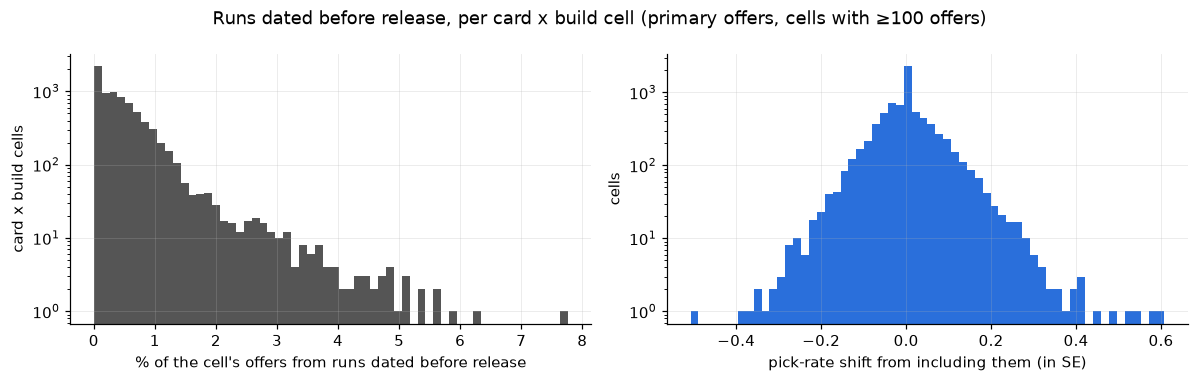

In [72]:
A = offers[offers.solo & offers.clean & offers.neow_start & offers.source.isin(CORE)]
t = (A.assign(k=A.n.where(A.picked, 0))
     .groupby(["card_id", "build_id", "before_release"])[["n", "k"]].sum()
     .unstack("before_release", fill_value=0))
n_f = t["n"].reindex(columns=[False, True], fill_value=0)
k_f = t["k"].reindex(columns=[False, True], fill_value=0)
chk = pd.DataFrame({"n_all": n_f.sum(axis=1), "n_flagged": n_f[True],
                    "k_all": k_f.sum(axis=1), "k_clean": k_f[False], "n_clean": n_f[False]})
chk = chk[chk.n_all >= 100]
chk["share_flagged"] = chk.n_flagged / chk.n_all
chk["p_all"] = chk.k_all / chk.n_all
chk["p_clean"] = chk.k_clean / chk.n_clean
chk["shift"] = chk.p_all - chk.p_clean
chk["shift_in_se"] = chk["shift"] / binom_se(chk.k_clean, chk.n_clean)

print(f"card x build cells with >=100 offers: {len(chk):,}")
print(f"flagged share of offers overall: {chk.n_flagged.sum() / chk.n_all.sum():.2%}")
print("flagged share per cell, quantiles:")
print(chk.share_flagged.quantile([0.5, 0.9, 0.99, 1]).map("{:.2%}".format).to_string())
print(f"|shift| in SE: median {chk.shift_in_se.abs().median():.3f}, "
      f"99th pct {chk.shift_in_se.abs().quantile(0.99):.3f}, max {chk.shift_in_se.abs().max():.3f}")
display(chk.sort_values("share_flagged", ascending=False)
        [["n_all", "n_flagged", "share_flagged", "p_all", "p_clean", "shift_in_se"]].head(15)
        .style.format({"share_flagged": "{:.1%}", "p_all": "{:.3f}", "p_clean": "{:.3f}",
                       "shift_in_se": "{:+.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(chk.share_flagged * 100, bins=60, color="#555")
axes[0].set(yscale="log", xlabel="% of the cell's offers from runs dated before release",
            ylabel="card x build cells")
axes[1].hist(chk.shift_in_se, bins=60, color="#2a6fdb")
axes[1].set(yscale="log", xlabel="pick-rate shift from including them (in SE)", ylabel="cells")
fig.suptitle("Runs dated before release, per card x build cell (primary offers, cells with ≥100 offers)")
fig.tight_layout()
plt.show()

### Do the uploader groups rank cards the same way?

In the largest stable build, each card's pick rate among tagged uploads (the SlayTheStats mod)
against untagged ones. Points along a line **parallel** to y = x mean one group is simply
pickier overall. The DiD's unchanged-card control absorbs that. Points **scattered** around
the line (low rank correlation) mean the groups rank cards differently, and a change in the mix
between them moves individual cards' pick rates. The control doesn't absorb that, so if the
groups differ, estimates are made within group or with uploader group as a covariate.

The per-card z-test (the cell after the power table, v0.107.1) puts a number on it: under "no
difference" the per-card z-scores are N(0, 1); their mean is the overall offset and their
spread beyond 1 is the ranking difference.

v0.107.1: 400 cards with ≥200 offers in both groups
Spearman rank correlation: 0.855
mean pick rate, tagged − untagged: -0.003


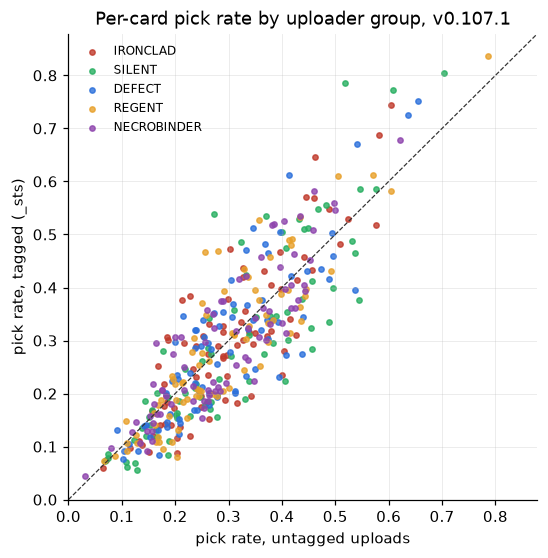

In [73]:
MIN_N = 200
stable = per_build[per_build.branch == "stable"]
BIG = stable.primary.idxmax()
G = O[O.build_id == BIG]
pr = (G.assign(k=G.n.where(G.picked, 0))
      .groupby(["card_id", "tagged"])[["n", "k"]].sum().unstack("tagged"))
pr = pr[(pr["n"].reindex(columns=[False, True]).fillna(0) >= MIN_N).all(axis=1)]
p_t, p_u = pr["k"][True] / pr["n"][True], pr["k"][False] / pr["n"][False]
main_char = (G.groupby(["card_id", "character"]).n.sum().reset_index()
             .sort_values("n").drop_duplicates("card_id", keep="last").set_index("card_id").character)

print(f"{BIG}: {len(pr)} cards with ≥{MIN_N} offers in both groups")
if len(pr) < 3:
    print("too few cards to compare; lower MIN_N")
else:
    print(f"Spearman rank correlation: {p_t.corr(p_u, method='spearman'):.3f}")
    print(f"mean pick rate, tagged − untagged: {(p_t - p_u).mean():+.3f}")

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    for ch in CHARS + ["other"]:
        ids = [c for c in pr.index if (main_char.get(c) if main_char.get(c) in CHARS else "other") == ch]
        if ids:
            ax.scatter(p_u[ids], p_t[ids], s=12, color=CHAR_COLOR.get(ch, "#aaa"), label=ch, alpha=0.8)
    lim = [0, max(p_t.max(), p_u.max()) * 1.05]
    ax.plot(lim, lim, color="#333", lw=0.8, ls="--")
    ax.set(xlim=lim, ylim=lim, xlabel="pick rate, untagged uploads", ylabel="pick rate, tagged (_sts)",
           title=f"Per-card pick rate by uploader group, {BIG}")
    ax.legend(frameon=False, fontsize=8)
    plt.show()

#### Selection or tooltips?

Two explanations for the ranking difference:

- **Selection:** players who install a stats mod are different players (more dedicated,
  different styles), whatever the mod shows them.
- **Tooltips:** the mod shows card stats while picking. Before v1.2.0 (June 19) that was only
  the player's *own* stats; community stats arrived with uploading in June. Many tagged runs
  were played before the mod was installed at all (uploaded later as backlog).

v0.103.2 was played mid-April to late May, before community tooltips existed; v0.107.1 from
June 18 on. About the same spread in both points to selection. A much larger spread in v0.107.1
points to the community tooltips. Caveat for both: offers aren't independent (one player can
upload hundreds of runs, and solo runs can't be grouped by player), so part of the spread can
be a few heavy uploaders' tastes. `gap beyond noise` is the typical per-card pick-rate gap left
after removing binomial noise.

In [74]:
def uploader_z(build, min_n=200):
    G = O[O.build_id == build]
    t = (G.assign(k=G.n.where(G.picked, 0))
         .groupby(["card_id", "tagged"])[["n", "k"]].sum().unstack("tagged"))
    t = t[(t["n"].reindex(columns=[False, True]).fillna(0) >= min_n).all(axis=1)]
    nt, nu = t["n"][True], t["n"][False]
    pt, pu = t["k"][True] / nt, t["k"][False] / nu
    p = (t["k"][True] + t["k"][False]) / (nt + nu)
    z = (pt - pu) / np.sqrt(p * (1 - p) * (1 / nt + 1 / nu))
    se2 = pt * (1 - pt) / nt + pu * (1 - pu) / nu
    gap = pt - pu
    return pd.DataFrame({"p_tagged": pt, "p_untagged": pu, "gap": gap, "z": z,
                         "se2": se2, "n_tagged": nt, "n_untagged": nu})

rows, per_card = [], {}
for b in ["v0.103.2", "v0.107.1"]:
    u = uploader_z(b)
    per_card[b] = u
    rows.append({
        "build": b, "cards": len(u), "mean z": u.z.mean(), "sd z": u.z.std(),
        "spearman": u.p_tagged.rank().corr(u.p_untagged.rank()),
        "gap beyond noise": np.sqrt(max(u.gap.var() - u.se2.mean(), 0)),
        "tagged offers": u.n_tagged.sum(), "untagged offers": u.n_untagged.sum(),
    })
display(pd.DataFrame(rows).set_index("build").style.format(
    {"mean z": "{:+.2f}", "sd z": "{:.2f}", "spearman": "{:.3f}", "gap beyond noise": "{:.3f}",
     "tagged offers": "{:,.0f}", "untagged offers": "{:,.0f}"}))

# Cards with the largest differences in each build
for b, u in per_card.items():
    print(f"\n{b}: largest |z|")
    display(u.reindex(u.z.abs().sort_values(ascending=False).index)
            [["p_tagged", "p_untagged", "gap", "z", "n_tagged", "n_untagged"]].head(10).round(3))

,cards,mean z,sd z,spearman,gap beyond noise,tagged offers,untagged offers
build,,,,,,,
v0.103.2,400,-0.85,3.75,0.927,0.046,"622,160","2,372,091"
v0.107.1,400,-0.54,4.95,0.855,0.074,"456,332","3,490,489"



v0.103.2: largest |z|


,p_tagged,p_untagged,gap,z,n_tagged,n_untagged
card_id,,,,,,
SETUP_STRIKE,0.098,0.204,-0.106,-15.263,3914.0,14606.0
POISONED_STAB,0.110,0.190,-0.080,-11.545,3805.0,14366.0
PERFECTED_STRIKE,0.199,0.292,-0.093,-11.462,3787.0,14717.0
FOOTWORK,0.634,0.473,0.161,11.042,1500.0,5564.0
SLICE,0.074,0.138,-0.064,-10.700,3861.0,14522.0
THUNDERCLAP,0.143,0.219,-0.076,-10.685,4078.0,14537.0
WELL_LAID_PLANS,0.428,0.288,0.140,10.433,1518.0,5663.0
ESCAPE_PLAN,0.595,0.444,0.150,9.974,1379.0,5425.0
BLADE_DANCE,0.304,0.389,-0.085,-9.802,3986.0,14277.0



v0.107.1: largest |z|


,p_tagged,p_untagged,gap,z,n_tagged,n_untagged
card_id,,,,,,
WELL_LAID_PLANS,0.539,0.272,0.266,17.693,1049.0,8353.0
FOOTWORK,0.786,0.519,0.267,16.458,1056.0,8492.0
SETUP_STRIKE,0.087,0.204,-0.117,-14.764,2782.0,22296.0
PERFECTED_STRIKE,0.182,0.316,-0.135,-14.470,2721.0,22283.0
CRESCENT_SPEAR,0.080,0.204,-0.124,-13.742,2149.0,16134.0
FLICK_FLACK,0.085,0.187,-0.102,-13.271,2759.0,21856.0
WISP,0.225,0.347,-0.123,-11.722,2297.0,17615.0
FEEL_NO_PAIN,0.376,0.213,0.163,11.610,1013.0,8313.0
DEFY,0.526,0.403,0.123,11.265,2305.0,17585.0


### First look: pick rate around a change

Pick rate per build for a few tweaked cards, with the character's other (unchanged) cards
as a gray baseline. This is the raw picture that the DiD formalizes: the card's line
should move at the change, and the baseline shouldn't. Beta builds are included, so the
change shows up at `beta_build` (orange line) before it reaches stable (blue line).
`CARDS` picks the four tweaked cards with the most offers; replace it with any card ids.

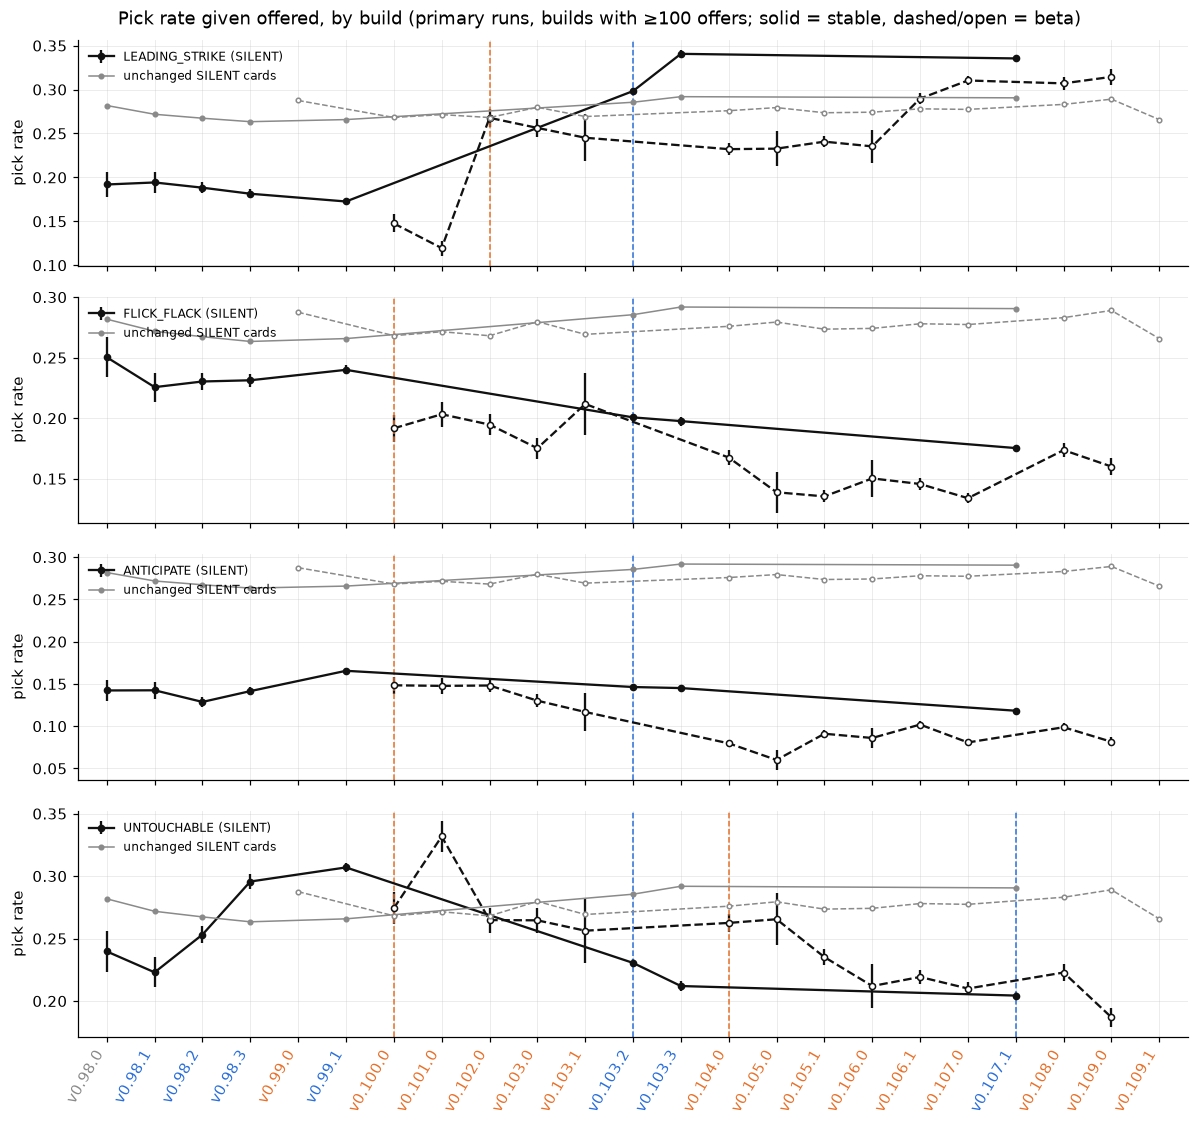

In [75]:
CARDS = (power.assign(n=power.n_pre + power.n_post).sort_values("n", ascending=False)
         .card_id.drop_duplicates().head(4).tolist())
changed_any = set(cc.card_id)

card_char = O.groupby(["card_id", "character"]).n.sum().reset_index() \
    .sort_values("n").drop_duplicates("card_id", keep="last").set_index("card_id").character

fig, axes = plt.subplots(len(CARDS), 1, figsize=(11, 2.6 * len(CARDS)), sharex=True, squeeze=False)
for ax, card in zip(axes[:, 0], CARDS):
    ch = card_char.get(card)
    branch_errorbar(ax, by_build.loc[card], "#111", f"{card} ({ch})", min_n=100)
    base = O[(O.character == ch) & ~O.card_id.isin(changed_any)]
    bb = pd.DataFrame({"n": base.groupby("build_id").n.sum(),
                       "k": base[base.picked].groupby("build_id").n.sum()}).fillna(0)
    branch_errorbar(ax, bb, "#8a8a8a", f"unchanged {ch} cards", min_n=100, err=False,
                    lw=1, ms=3)
    for r in tw[tw.card_id == card].itertuples():
        for b, color in [(r.beta_build, "#e8702a"), (r.stable_build, "#2a6fdb")]:
            if b in BUILD_ORDER:
                ax.axvline(BUILD_ORDER.index(b), color=color, lw=1, ls="--")
    ax.set_ylabel("pick rate")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
build_axis(axes[-1, 0])
fig.suptitle("Pick rate given offered, by build (primary runs, builds with ≥100 offers; "
             "solid = stable, dashed/open = beta)")
fig.tight_layout()
plt.show()

## Where the decisions went

The audit's decisions are in `SPIROMETRY.md` → **Audit decisions** (filters, thin builds,
beta/stable overlap for the staggered rollout, snapshot reach and backfill, uploader groups)
and in the `PLAN.md` decision log. Still open: the backfill numbers above go into
SPIROMETRY.md once this has been rerun on the finished snapshot; the audit moves to the
Phase 3 run tables once they're built on the full snapshot.